# Poisson regression applied to AIDS cases in Belgium

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm

This example considers the number of cases of AIDS in Belgium (data from the 80's).

We assume that a Poisson model is razonable (See book of Wood S.S. (2006) Generalized Additive Models).

In [2]:
dat = pd.read_csv('aids_cases_belgium.csv')

years = dat['year']
cases = dat['cases']

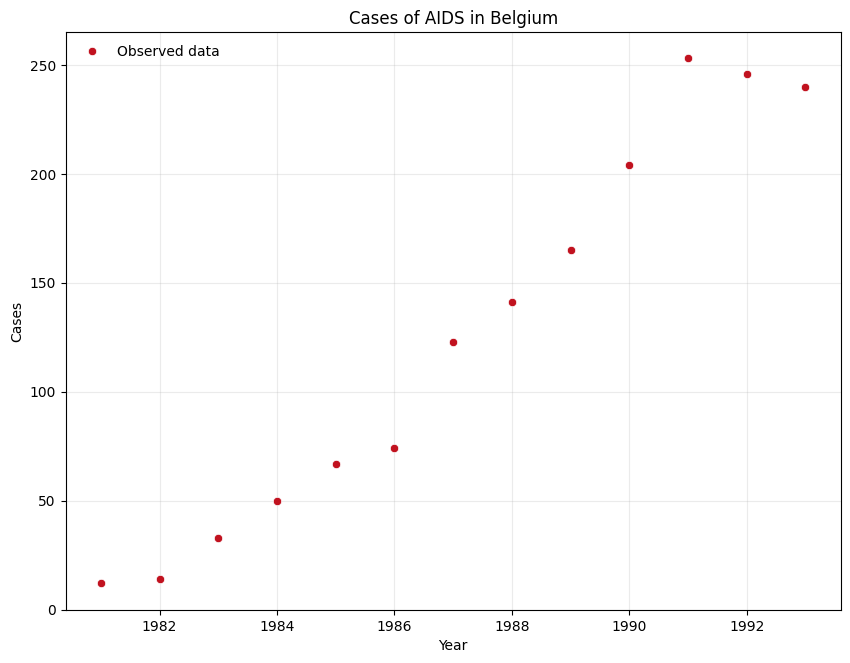

In [3]:
plt.figure(figsize=(10, 7.5))
plt.plot(years, cases, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('Cases')
plt.title('Cases of AIDS in Belgium')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Poisson regression by hand

In [4]:
n = len(cases)

x = years - 1981
X = np.vstack([np.ones(n), x]).T

b = [3,0.2] # initial values

tolm   = 1e-6       # tolerance (minimum norm of the difference of the betas)
iterm  = 100        # maximum number of iterations
tolera = 1          # initialize tolera
itera  = 0          # initialize ittera
histo  = b          # initialize beta upgrade

while((tolera > tolm) and (itera < iterm)):
  lam    = np.exp(X @ b)
  D      = np.diag(lam)
  var_b  = np.linalg.inv(X.T @ D @ X)
  delta  = var_b @ X.T @ (cases-lam)
  b      = b+delta
  tolera = np.sqrt(sum(delta**2))
  histo  = np.vstack([histo, b])
  itera  = itera+1

histo

array([[3.        , 0.2       ],
       [3.40863828, 0.20303375],
       [3.344822  , 0.20218496],
       [3.34271289, 0.20212137],
       [3.34271074, 0.2021212 ],
       [3.34271074, 0.2021212 ]])

In [5]:
# Significance of the estimators
se_b = np.sqrt(np.diag(var_b))
z_score = b/se_b
p_value = 2*(1-norm.cdf(np.abs(z_score)))

z_score, p_value

(array([47.1335028 , 26.00802964]), array([0., 0.]))

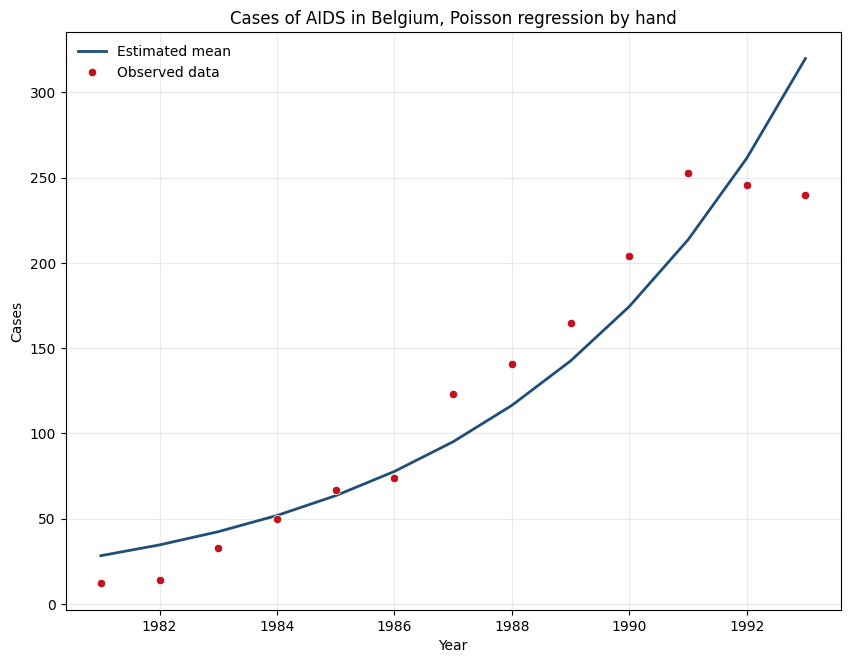

In [6]:
plt.figure(figsize=(10, 7.5))

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(years, lam, color='#1f4e79', lw=2, label='Estimated mean')

# Observed data on top, dark and distinct
plt.plot(years, cases, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('Cases')
plt.title('Cases of AIDS in Belgium, Poisson regression by hand')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Using sm

In [7]:
# --- fit the model ---
poisson_model = sm.GLM(cases, X, family=sm.families.Poisson())
poisson_results = poisson_model.fit()

beta_hat = poisson_results.params

In [8]:
np.ravel(beta_hat) 

array([3.34271074, 0.2021212 ])

### Adding confidence intervals to the Poisson curve

In [9]:
alpha = 0.05
z = norm.ppf(1-alpha/2)

In [10]:
# --- dense grid between first and last year ---
n_grid = 200
x_grid = np.linspace(x.min(), x.max(), n_grid)
years_grid = np.linspace(years.min(), years.max(), n_grid)

# --- create X and X_grid matrices ---
X_grid = np.vstack([np.ones(n_grid), x_grid]).T

In [11]:
# --- eta_hat and confidence intervals ---
Sigma   = poisson_results.cov_params()
eta_hat = X_grid @ beta_hat
sd_eta  = np.sqrt(np.diag(X_grid @ Sigma @ X_grid.T))
ci_eta_lower = eta_hat - z*sd_eta
ci_eta_upper = eta_hat + z*sd_eta

# --- lam_hat and confidence intervals ---
lam_hat = np.exp(eta_hat)
ci_lam_lower = np.exp(ci_eta_lower)
ci_lam_upper = np.exp(ci_eta_upper)

# --- Prediction interval for new counts (parametric bootstrap) ---
B = 10000
rng = np.random.default_rng(0)
beta_draws = rng.multivariate_normal(beta_hat, Sigma, size=B)
lam_draws  = np.exp(beta_draws @ X_grid.T)
y_draws    = rng.poisson(lam_draws)
pi_lower = np.quantile(y_draws, alpha/2,   axis=0)
pi_upper = np.quantile(y_draws, 1 - alpha/2, axis=0)

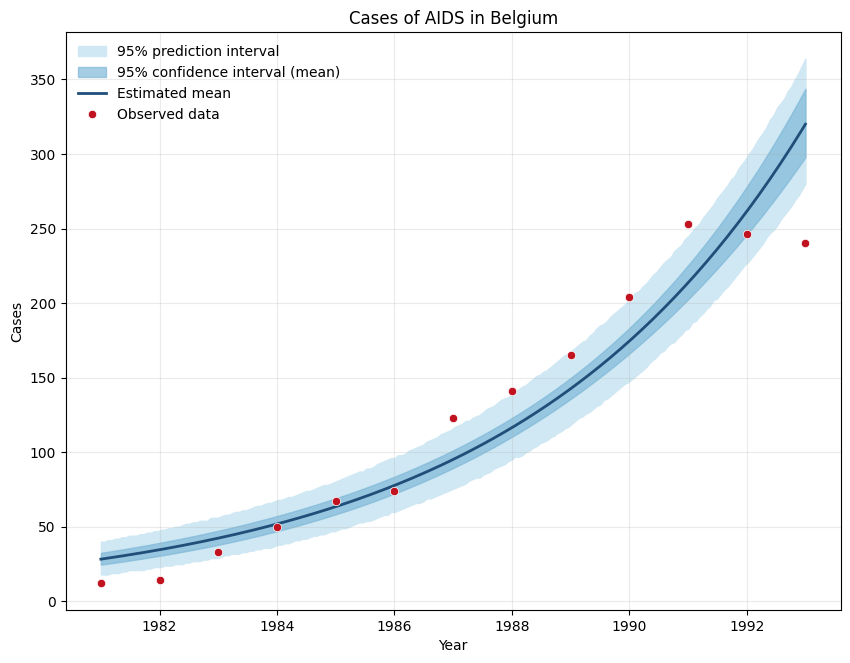

In [12]:
plt.figure(figsize=(10, 7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(years_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(years_grid, ci_lam_lower, ci_lam_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(years_grid, lam_hat, color='#1f4e79', lw=2, label='Estimated mean')

# Observed data on top, dark and distinct
plt.plot(years, cases, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('Cases')
plt.title('Cases of AIDS in Belgium')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

In the Poisson regression, we model $\log\lambda = \beta^TX$, we can use this as a graphical way to inspect the goodness-of-fit

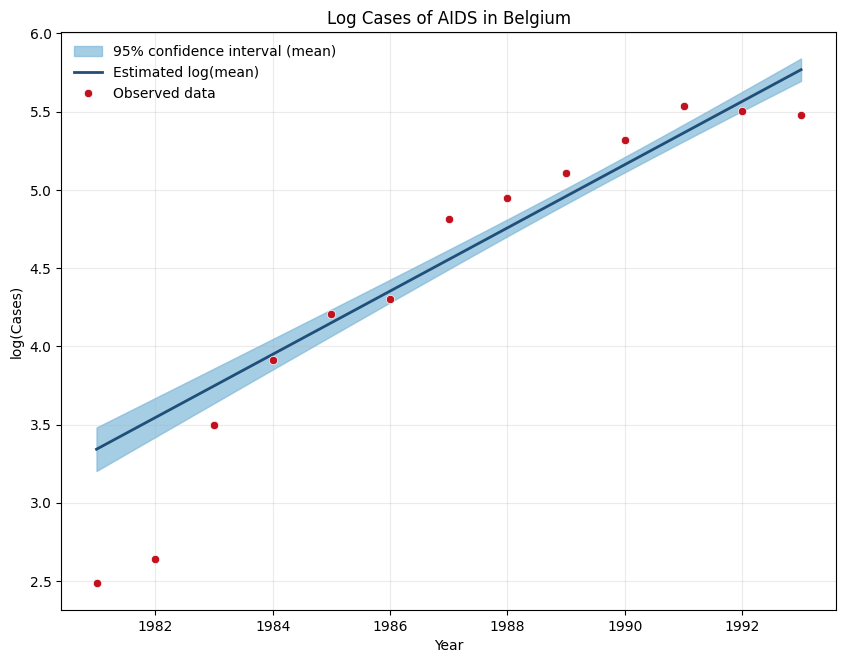

In [13]:
plt.figure(figsize=(10, 7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'

plt.fill_between(years_grid, ci_eta_lower, ci_eta_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(years_grid, eta_hat, color='#1f4e79', lw=2, label='Estimated log(mean)')

# Observed data on top, dark and distinct
plt.plot(years, np.log(cases), 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('log(Cases)')
plt.title('Log Cases of AIDS in Belgium')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## A quadratic model will do it better

In [14]:
# --- fit the model ---
X = np.vstack([np.ones(n), x, x**2]).T
X_grid = np.vstack([np.ones(n_grid), x_grid, x_grid**2]).T

poisson_model = sm.GLM(cases, X, family=sm.families.Poisson())
poisson_results = poisson_model.fit()

beta_hat = poisson_results.params

In [15]:
# --- eta_hat and confidence intervals ---
Sigma   = poisson_results.cov_params()
eta_hat = X_grid @ beta_hat
sd_eta  = np.sqrt(np.diag(X_grid @ Sigma @ X_grid.T))
ci_eta_lower = eta_hat - z*sd_eta
ci_eta_upper = eta_hat + z*sd_eta

# --- lam_hat and confidence intervals ---
lam_hat = np.exp(eta_hat)
ci_lam_lower = np.exp(ci_eta_lower)
ci_lam_upper = np.exp(ci_eta_upper)

# --- Prediction interval for new counts (parametric bootstrap) ---
B = 10000
rng = np.random.default_rng(0)
beta_draws = rng.multivariate_normal(beta_hat, Sigma, size=B)
lam_draws  = np.exp(beta_draws @ X_grid.T)
y_draws    = rng.poisson(lam_draws)
pi_lower = np.quantile(y_draws, alpha/2,   axis=0)
pi_upper = np.quantile(y_draws, 1 - alpha/2, axis=0)

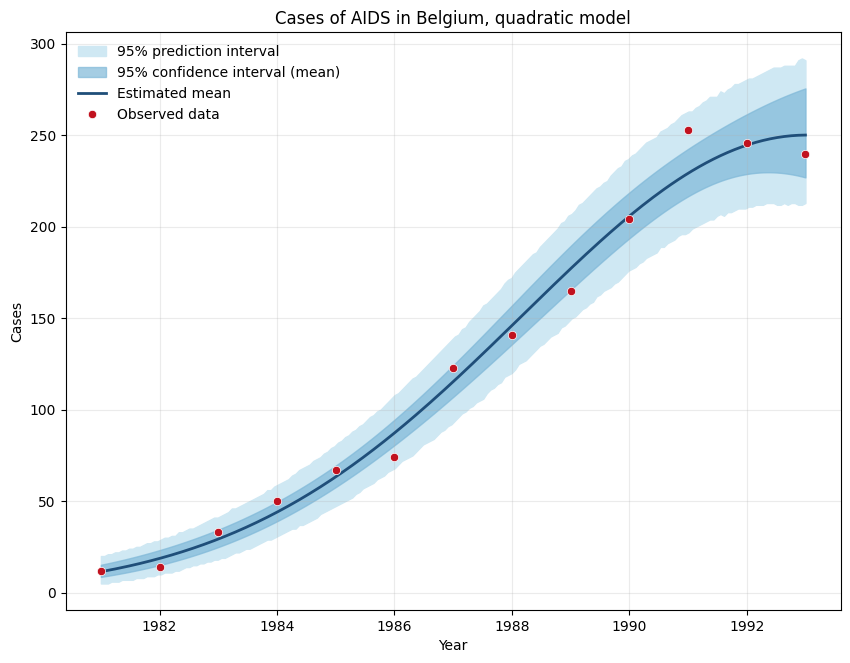

In [16]:
plt.figure(figsize=(10, 7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(years_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(years_grid, ci_lam_lower, ci_lam_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(years_grid, lam_hat, color='#1f4e79', lw=2, label='Estimated mean')

# Observed data on top, dark and distinct
plt.plot(years, cases, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('Cases')
plt.title('Cases of AIDS in Belgium, quadratic model')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

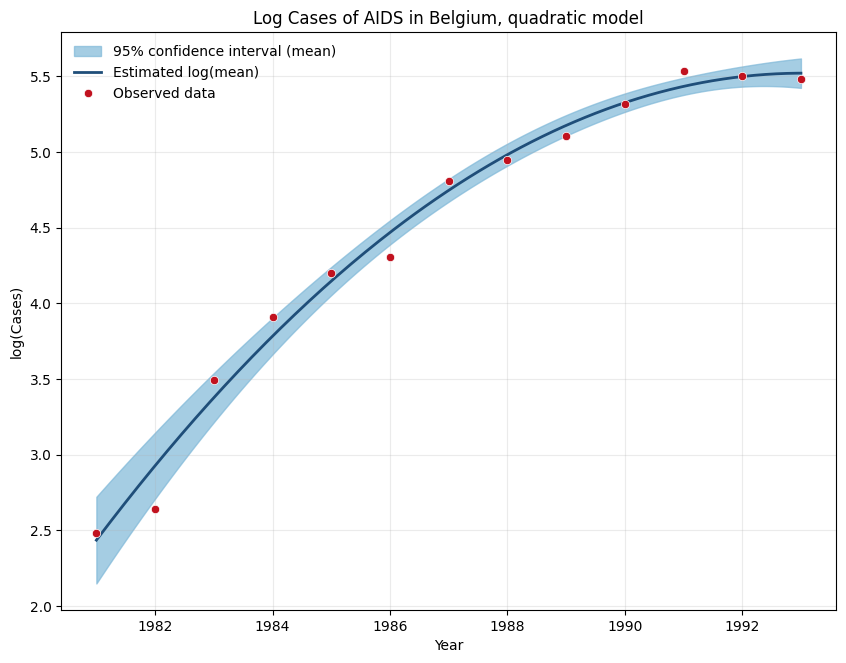

In [17]:
plt.figure(figsize=(10, 7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'

plt.fill_between(years_grid, ci_eta_lower, ci_eta_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(years_grid, eta_hat, color='#1f4e79', lw=2, label='Estimated log(mean)')

# Observed data on top, dark and distinct
plt.plot(years, np.log(cases), 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Year')
plt.ylabel('log(Cases)')
plt.title('Log Cases of AIDS in Belgium, quadratic model')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)